# Notebook de Preparação dos Dados para a Pipeline do Modelo

Este notebook reúne os passos necessários para explorar, organizar e preparar os dados de coordenadas das mãos capturados com o **HandLandmark do MediaPipe**.

Nosso objetivo é transformar essas coordenadas em um conjunto de dados consistente e bem estruturado, pronto para treinar modelos de **machine learning** capazes de classificar letras da **Libras** com maior precisão.

Ao longo do notebook, vamos seguir uma sequência clara de trabalho: entender a origem dos dados, inspecionar sua estrutura, tratar possíveis inconsistências e preparar tudo para a etapa de treinamento do modelo.

## Passo a passo

1. **Carregar os dados**
   - Importar os arquivos ou tabelas com as coordenadas das mãos.
   - Verificar se os dados foram lidos corretamente.

2. **Entender a estrutura do conjunto de dados**
   - Conferir colunas, tipos de dados e quantidade de registros.
   - Identificar quais atributos representam os pontos da mão.

3. **Fazer uma análise inicial**
   - Verificar valores ausentes, dados duplicados e possíveis inconsistências.
   - Observar a distribuição das classes, como letras ou sinais.

4. **Limpar e organizar os dados**
   - Tratar valores nulos e remover duplicatas, se necessário.
   - Padronizar nomes de colunas e formatos.

5. **Engenharia de Features**
   - Calcular a distância euclidiana entre as pontas dos dedos e o pulso.

6. **Preparar as variáveis para o modelo**
   - Separar entrada e saída.
   - Manter as coordenadas e as novas distâncias como variáveis de entrada.

7. **Dividir os dados para treino e teste**
   - Criar conjuntos de treino, validação e teste.
   - Garantir que a divisão seja representativa.

8. **Salvar a versão final preparada**
   - Exportar o dataset tratado para uso na pipeline de treinamento.
   - Registrar decisões importantes tomadas durante a preparação.

In [21]:
!pip install "matplotlib>=3.10.9" "pandas>=3.0.3" "seaborn>=0.13.2"

### Imports

In [22]:
# Imports
import json
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", palette="deep")

# Caminhos dos arquivos
# Funciona tanto se o notebook for executado a partir da raiz do projeto
# quanto se for executado de dentro da pasta notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_separated = PROJECT_ROOT / "data" / "data_separated"
data_output = PROJECT_ROOT / "data" / "data_output"

RANDOM_STATE = 42
LABEL_COLUMN = "label"


## 1. **Carregar os dados**
   - Importar os arquivos ou tabelas com as coordenadas das mãos.
   - Verificar se os dados foram lidos corretamente.


In [23]:
def concat_tables(data_input, data_output):
    dfs = []

    for item in sorted(data_input.glob("*.csv")):
        df_temp = pd.read_csv(item)
        df_temp["source_file"] = item.name
        dfs.append(df_temp)

    if not dfs:
        raise FileNotFoundError(f"Nenhum arquivo CSV encontrado em {data_input}")

    df = pd.concat(dfs, ignore_index=True)

    data_output.mkdir(parents=True, exist_ok=True)
    output_file = data_output / "dataset_concatenado.csv"
    df.to_csv(output_file, index=False)

    return df


In [24]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

pastas_necessarias = [
    PROJECT_ROOT / "data" / "data_separated",           # CSVs brutos extraídos do MediaPipe
    PROJECT_ROOT / "data" / "data_output" / "prepared",  # Saída limpa do notebook de preparação
    PROJECT_ROOT / "data" / "data_output" / "engineered",# Saída do motor geométrico 3D
    PROJECT_ROOT / "assets" / "models",                  # Diretório de exportação do modelo (.pkl)
]

for pasta in pastas_necessarias:
    pasta.mkdir(parents=True, exist_ok=True)
    print(f"Verificado: {pasta.relative_to(PROJECT_ROOT)}")


Verificado: data/data_separated
Verificado: data/data_output/prepared
Verificado: data/data_output/engineered
Verificado: assets/models


In [25]:
df = concat_tables(data_separated, data_output)
df.head()


,label,x0,y0,z0,x1,y1,z1,x2,y2,z2,...,x18,y18,z18,x19,y19,z19,x20,y20,z20,source_file
0,A,0.0,0.0,0.0,-0.279288,-0.165591,-0.079699,-0.521103,-0.502658,-0.117389,...,0.226257,-0.859783,-0.184327,0.174208,-0.622645,-0.131428,0.169268,-0.501116,-0.068995,datasetAMEP.csv
1,A,0.0,0.0,0.0,-0.230183,-0.162898,-0.086023,-0.429579,-0.515378,-0.107071,...,0.177663,-0.825861,-0.098269,0.129152,-0.638704,-0.045937,0.151294,-0.609237,0.011671,datasetAMEP.csv
2,A,0.0,0.0,0.0,-0.216314,-0.150896,-0.082746,-0.414731,-0.511850,-0.101263,...,0.175588,-0.827686,-0.092815,0.130033,-0.650662,-0.038147,0.156966,-0.628454,0.019171,datasetAMEP.csv
3,A,0.0,0.0,0.0,-0.221650,-0.154646,-0.086122,-0.424169,-0.509196,-0.106448,...,0.184436,-0.820161,-0.087063,0.137433,-0.646774,-0.034385,0.164424,-0.629382,0.020973,datasetAMEP.csv
4,A,0.0,0.0,0.0,-0.220164,-0.151683,-0.093979,-0.428585,-0.511275,-0.116125,...,0.182142,-0.832294,-0.085049,0.135735,-0.652420,-0.033953,0.161024,-0.638898,0.020778,datasetAMEP.csv


## 2. **Entender a estrutura do conjunto de dados**
   - Conferir colunas, tipos de dados e quantidade de registros.
   - Identificar quais atributos representam os pontos da mão.


In [26]:
landmark_columns = [col for col in df.columns if col != LABEL_COLUMN and col != "source_file"]
expected_landmark_columns = [f"{axis}{idx}" for idx in range(21) for axis in ("x", "y", "z")]
missing_landmark_columns = sorted(set(expected_landmark_columns) - set(landmark_columns))
extra_landmark_columns = sorted(set(landmark_columns) - set(expected_landmark_columns))

estrutura = pd.DataFrame(
    {
        "metrica": [
            "linhas",
            "colunas",
            "classes",
            "features_landmarks",
            "colunas_landmarks_ausentes",
            "colunas_landmarks_extras",
        ],
        "valor": [
            len(df),
            df.shape[1],
            df[LABEL_COLUMN].nunique(),
            len(landmark_columns),
            missing_landmark_columns,
            extra_landmark_columns,
        ],
    }
)

estrutura


,metrica,valor
0,linhas,27444
1,colunas,65
2,classes,20
3,features_landmarks,63
4,colunas_landmarks_ausentes,[]
5,colunas_landmarks_extras,[]


In [27]:
df.dtypes.value_counts()


float64    63
str         2
Name: count, dtype: int64

## 3. **Fazer uma análise inicial**
   - Verificar valores ausentes, dados duplicados e possíveis inconsistências.
   - Observar a distribuição das classes, como letras ou sinais.


In [28]:
qualidade = pd.DataFrame(
    {
        "metrica": [
            "valores_ausentes",
            "linhas_duplicadas",
            "labels_ausentes",
            "arquivos_origem",
        ],
        "valor": [
            int(df.isna().sum().sum()),
            int(df.duplicated().sum()),
            int(df[LABEL_COLUMN].isna().sum()),
            df["source_file"].nunique(),
        ],
    }
)

qualidade


,metrica,valor
0,valores_ausentes,0
1,linhas_duplicadas,0
2,labels_ausentes,0
3,arquivos_origem,6


In [29]:
class_counts = df[LABEL_COLUMN].value_counts().sort_index()
class_counts.to_frame("quantidade")


,quantidade
label,
A,1883
B,1100
C,1025
D,1007
E,1140
F,2698
G,1008
I,1003
L,1222


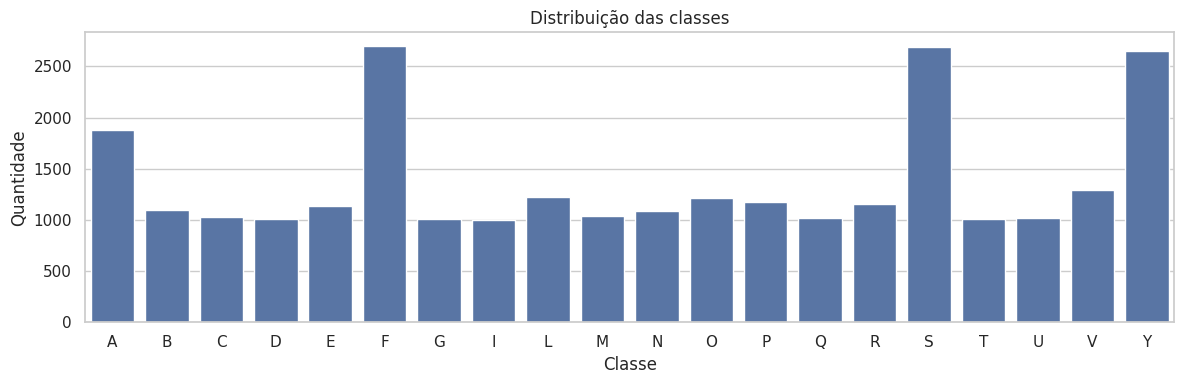

In [30]:
plt.figure(figsize=(12, 4))
sns.countplot(data=df, x=LABEL_COLUMN, order=class_counts.index)
plt.title("Distribuição das classes")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. **Limpar e organizar os dados**
   - Tratar valores nulos e remover duplicatas, se necessário.
   - Padronizar nomes de colunas e formatos.


In [31]:
def clean_dataset(df, label_column=LABEL_COLUMN):
    df_clean = df.copy()
    df_clean.columns = df_clean.columns.str.strip()

    df_clean[label_column] = (
        df_clean[label_column]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    feature_columns = [col for col in df_clean.columns if col not in [label_column, "source_file"]]
    df_clean[feature_columns] = df_clean[feature_columns].apply(pd.to_numeric, errors="coerce")

    rows_before = len(df_clean)
    df_clean = df_clean.dropna(subset=[label_column, *feature_columns])
    df_clean = df_clean.reset_index(drop=True)

    cleaning_report = {
        "linhas_antes": rows_before,
        "linhas_depois": len(df_clean),
        "linhas_removidas": rows_before - len(df_clean),
        "valores_ausentes_restantes": int(df_clean[[label_column, *feature_columns]].isna().sum().sum()),
    }

    return df_clean, feature_columns, cleaning_report


df_clean, feature_columns, cleaning_report = clean_dataset(df)
cleaning_report


{'linhas_antes': 27444,
 'linhas_depois': 27444,
 'linhas_removidas': 0,
 'valores_ausentes_restantes': 0}

In [32]:
df_clean[LABEL_COLUMN].value_counts().sort_index().to_frame("quantidade")


,quantidade
label,
A,1883
B,1100
C,1025
D,1007
E,1140
F,2698
G,1008
I,1003
L,1222


## 5. **Engenharia de Features**
   - Calcular a distância euclidiana entre as pontas dos dedos e o pulso.

In [33]:
import numpy as np

def aplicar_engenharia_avancada_no_notebook(df):
    df_features = df.copy()

    def calc_dist(p1, p2):
        return np.sqrt(
            (df_features[f'x{p1}'] - df_features[f'x{p2}'])**2 +
            (df_features[f'y{p1}'] - df_features[f'y{p2}'])**2 +
            (df_features[f'z{p1}'] - df_features[f'z{p2}'])**2
        )

    def calc_angulo(base, p1, p2):
        v1_x = df_features[f'x{p1}'] - df_features[f'x{base}']
        v1_y = df_features[f'y{p1}'] - df_features[f'y{base}']
        v1_z = df_features[f'z{p1}'] - df_features[f'z{base}']
        v2_x = df_features[f'x{p2}'] - df_features[f'x{base}']
        v2_y = df_features[f'y{p2}'] - df_features[f'y{base}']
        v2_z = df_features[f'z{p2}'] - df_features[f'z{base}']
        dot_product = (v1_x * v2_x) + (v1_y * v2_y) + (v1_z * v2_z)
        mag1 = np.sqrt(v1_x**2 + v1_y**2 + v1_z**2)
        mag2 = np.sqrt(v2_x**2 + v2_y**2 + v2_z**2)
        cos_theta = np.clip(dot_product / (mag1 * mag2 + 1e-7), -1.0, 1.0)
        return np.degrees(np.arccos(cos_theta))

    # --- Normalizadores intrínsecos da mão (não usam dados externos) ---
    tamanho_mao  = calc_dist(0, 9)  + 1e-7
    comp_polegar = calc_dist(2, 4)  + 1e-7

    # --- Dedos levantados ---
    df_features['polegar_up']   = (calc_dist(4, 2) > calc_dist(3, 2)).astype(int)
    df_features['indicador_up'] = (calc_dist(8, 0) > calc_dist(6, 0)).astype(int)
    df_features['medio_up']     = (calc_dist(12, 0) > calc_dist(10, 0)).astype(int)
    df_features['anelar_up']    = (calc_dist(16, 0) > calc_dist(14, 0)).astype(int)
    df_features['minimo_up']    = (calc_dist(20, 0) > calc_dist(18, 0)).astype(int)
    df_features['qtd_dedos_up'] = df_features[
        ['polegar_up', 'indicador_up', 'medio_up', 'anelar_up', 'minimo_up']
    ].sum(axis=1)

    # --- Distâncias relativas das pontas ao pulso ---
    df_features['dist_rel_polegar']  = calc_dist(4,  0) / tamanho_mao
    df_features['dist_rel_indicador']= calc_dist(8,  0) / tamanho_mao
    df_features['dist_rel_medio']    = calc_dist(12, 0) / tamanho_mao
    df_features['dist_rel_anelar']   = calc_dist(16, 0) / tamanho_mao
    df_features['dist_rel_minimo']   = calc_dist(20, 0) / tamanho_mao

    # --- Ângulos entre dedos adjacentes (visto do pulso) ---
    df_features['angulo_pol_ind'] = calc_angulo(0, 4,  8)
    df_features['angulo_ind_med'] = calc_angulo(0, 8,  12)
    df_features['angulo_med_ane'] = calc_angulo(0, 12, 16)
    df_features['angulo_ane_min'] = calc_angulo(0, 16, 20)

    # --- Profundidade relativa (eixo Z: apontando para câmera) ---
    df_features['z_aponta_cam_ind'] = (df_features['z8']  - df_features['z0']) / tamanho_mao
    df_features['z_aponta_cam_pol'] = (df_features['z4']  - df_features['z0']) / tamanho_mao

    # --- Distâncias entre pontas de dedos adjacentes ---
    df_features['dist_pol_ind'] = calc_dist(4,  8)  / tamanho_mao
    df_features['dist_ind_med'] = calc_dist(8,  12) / tamanho_mao
    df_features['dist_med_ane'] = calc_dist(12, 16) / tamanho_mao
    df_features['dist_ane_min'] = calc_dist(16, 20) / tamanho_mao
    df_features['dist_pol_min'] = calc_dist(4,  20) / tamanho_mao

    # --- Curvatura interna de cada dedo ---
    df_features['curva_polegar']   = calc_angulo(1,  2,  3)
    df_features['curva_indicador'] = calc_angulo(5,  6,  7)
    df_features['curva_medio']     = calc_angulo(9,  10, 11)
    df_features['curva_anelar']    = calc_angulo(13, 14, 15)
    df_features['curva_minimo']    = calc_angulo(17, 18, 19)

    # --- Normal da palma (orientação 3D da mão) ---
    v_palma_x = df_features['x5']  - df_features['x0']
    v_palma_y = df_features['y5']  - df_features['y0']
    v_palma_z = df_features['z5']  - df_features['z0']
    v_min_x   = df_features['x17'] - df_features['x0']
    v_min_y   = df_features['y17'] - df_features['y0']
    v_min_z   = df_features['z17'] - df_features['z0']

    df_features['normal_palma_x'] = v_palma_y * v_min_z - v_palma_z * v_min_y
    df_features['normal_palma_y'] = v_palma_z * v_min_x - v_palma_x * v_min_z
    df_features['normal_palma_z'] = v_palma_x * v_min_y - v_palma_y * v_min_x

    mag_normal = np.sqrt(
        df_features['normal_palma_x']**2 +
        df_features['normal_palma_y']**2 +
        df_features['normal_palma_z']**2
    ) + 1e-7
    df_features['normal_palma_x'] /= mag_normal
    df_features['normal_palma_y'] /= mag_normal
    df_features['normal_palma_z'] /= mag_normal

    # --- Distâncias polegar → outros dedos (normalizadas pelo próprio polegar) ---
    df_features['dist_pol_med']     = calc_dist(4, 12) / comp_polegar
    df_features['dist_pol_ane']     = calc_dist(4, 16) / comp_polegar
    df_features['dist_pol_min_tip'] = calc_dist(4, 20) / comp_polegar

    # --- Remove coordenadas brutas (x0..z20): não são mais necessárias ---
    colunas_brutas = [f"{eixo}{i}" for i in range(21) for eixo in ['x', 'y', 'z']]
    df_final = df_features.drop(columns=colunas_brutas, errors='ignore')

    return df_final.round(4)


# ── Execução ──────────────────────────────────────────────────────────────────
df_com_geometria = aplicar_engenharia_avancada_no_notebook(df_clean)

feature_columns = [
    col for col in df_com_geometria.columns
    if col not in [LABEL_COLUMN, 'source_file']
]

print(f"Features geradas : {len(feature_columns)}")
print(f"Shape do dataset : {df_com_geometria.shape}")
df_com_geometria.head()

Features geradas : 33
Shape do dataset : (27444, 35)


,label,source_file,polegar_up,indicador_up,medio_up,anelar_up,minimo_up,qtd_dedos_up,dist_rel_polegar,dist_rel_indicador,...,curva_indicador,curva_medio,curva_anelar,curva_minimo,normal_palma_x,normal_palma_y,normal_palma_z,dist_pol_med,dist_pol_ane,dist_pol_min_tip
0,A,datasetAMEP.csv,1,0,0,0,0,1,1.3439,0.6977,...,74.4291,78.7502,84.5589,104.3192,0.2046,-0.0681,0.9765,1.4952,1.7514,1.9545
1,A,datasetAMEP.csv,1,0,0,0,0,1,1.4150,0.8612,...,83.6399,95.9553,105.5695,111.5314,0.1840,-0.0086,0.9829,1.3594,1.6628,1.9335
2,A,datasetAMEP.csv,1,0,0,0,0,1,1.4143,0.8895,...,88.6318,101.3761,111.8115,114.5590,0.1695,-0.0171,0.9854,1.3588,1.6794,1.9508
3,A,datasetAMEP.csv,1,0,0,0,0,1,1.4204,0.8816,...,88.1946,98.8016,110.1923,117.8224,0.1515,-0.0154,0.9883,1.3781,1.6935,1.9642
4,A,datasetAMEP.csv,1,0,0,0,0,1,1.3908,0.8657,...,92.2698,98.7001,109.6282,121.7469,0.1359,-0.0103,0.9907,1.3910,1.7132,1.9896


## 6. ~~Preparar as variáveis para o modelo~~ → **Etapa removida**

> ⚠️ **Esta seção foi descontinuada na refatoração anti-leakage.**
>
> Anteriormente, separávamos `X` e `y` aqui para alimentar diretamente um modelo.
> Com a nova arquitetura, essa separação acontece dentro do notebook de treinamento
> (`training_pipeline.ipynb`), **após** o split cronológico e a engenharia geométrica.
> As saídas prontas para treino já estão em `data/data_output/engineered/`.


## 7. **Dividir os dados para treino, validação e teste**
   - Criar conjuntos estratificados para preservar a proporção das classes.
   - Calcular estatísticas de padronização usando apenas o treino.


In [34]:
def stratified_split_cronologico(
    df,
    label_column=LABEL_COLUMN,
    test_size=0.15,
    val_size=0.15,
):
    """
    Divide cada vídeo/arquivo-fonte em [treino | validação | teste]
    respeitando a ordem cronológica dos frames.

    Por que isso importa:
      - Frames consecutivos são capturados com milissegundos de diferença.
      - Um split aleatório joga frames vizinhos em splits diferentes,
        vazando contexto temporal (Data Leakage Temporal).
      - Aqui, os primeiros 70 % de cada vídeo vão para treino,
        os próximos 15 % para validação e os últimos 15 % para teste.
      - Após o corte cronológico, CADA SPLIT é embaralhado internamente —
        isso é seguro porque o embaralhamento não cruza os splits.
    """
    train_list, val_list, test_list = [], [], []

    for source, group in df.groupby('source_file'):
        n = len(group)
        idx_train = int(n * (1 - test_size - val_size))
        idx_val   = int(n * (1 - test_size))

        train_list.append(group.iloc[:idx_train])
        val_list.append(group.iloc[idx_train:idx_val])
        test_list.append(group.iloc[idx_val:])

    train_df = pd.concat(train_list).reset_index(drop=True)
    val_df   = pd.concat(val_list).reset_index(drop=True)
    test_df  = pd.concat(test_list).reset_index(drop=True)

    # Embaralhamento interno a cada split (seguro — não cruza fronteiras)
    train_df = train_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    val_df   = val_df.sample(frac=1,   random_state=RANDOM_STATE).reset_index(drop=True)
    test_df  = test_df.sample(frac=1,  random_state=RANDOM_STATE).reset_index(drop=True)

    return train_df, val_df, test_df


# ── Execução ──────────────────────────────────────────────────────────────────
train_df, val_df, test_df = stratified_split_cronologico(df_com_geometria)

split_summary = pd.DataFrame({
    'split'      : ['treino', 'validacao', 'teste'],
    'linhas'     : [len(train_df), len(val_df), len(test_df)],
    'percentual' : [
        len(train_df) / len(df_com_geometria),
        len(val_df)   / len(df_com_geometria),
        len(test_df)  / len(df_com_geometria),
    ],
})

split_summary

,split,linhas,percentual
0,treino,19208,0.699898
1,validacao,4117,0.150015
2,teste,4119,0.150087


In [35]:
pd.concat(
    {
        "treino": train_df[LABEL_COLUMN].value_counts(normalize=True).sort_index(),
        "validacao": val_df[LABEL_COLUMN].value_counts(normalize=True).sort_index(),
        "teste": test_df[LABEL_COLUMN].value_counts(normalize=True).sort_index(),
    },
    axis=1,
).fillna(0).round(4)


,treino,validacao,teste
label,,,
A,0.098,0.0,0.0
B,0.0474,0.0459,0.0
C,0.0534,0.0,0.0
D,0.0524,0.0,0.0
E,0.0594,0.0,0.0
F,0.1211,0.0904,0.0
G,0.0419,0.0496,0.0
I,0.0522,0.0,0.0
L,0.0636,0.0,0.0


## 8. **Salvar a versão final preparada**
   - Exportar o dataset tratado para uso na pipeline de treinamento.
   - Registrar decisões importantes tomadas durante a preparação.


In [36]:
# ── Diretórios de saída ───────────────────────────────────────────────────────
prepared_output  = data_output / "prepared"
engineered_output = data_output / "engineered"
prepared_output.mkdir(parents=True, exist_ok=True)
engineered_output.mkdir(parents=True, exist_ok=True)

# ── Exportação dos arquivos ───────────────────────────────────────────────────
# Dataset limpo (coordenadas brutas, pré-engenharia) — referência de auditoria
df_clean.to_csv(prepared_output / "dataset_limpo.csv", index=False)

# Dataset com geometria 3D completa (sem standardização — features já são
# invariantes à escala por construção)
df_com_geometria.to_csv(engineered_output / "dataset_geometrico.csv", index=False)

# Splits cronológicos prontos para treino
train_df.to_csv(engineered_output / "train.csv",      index=False)
val_df.to_csv(  engineered_output / "validation.csv", index=False)
test_df.to_csv( engineered_output / "test.csv",       index=False)

# ── Metadados da pipeline ─────────────────────────────────────────────────────
metadata = {
    "label_column"   : LABEL_COLUMN,
    "feature_columns": feature_columns,
    "n_features"     : len(feature_columns),
    "classes"        : sorted(df_com_geometria[LABEL_COLUMN].unique().tolist()),
    "random_state"   : RANDOM_STATE,
    "split_strategy" : "chronological_by_source_file",
    "split_ratios"   : {"train": 0.70, "validation": 0.15, "test": 0.15},
    "split_rows"     : {
        "train"     : len(train_df),
        "validation": len(val_df),
        "test"      : len(test_df),
    },
    "cleaning_report": cleaning_report,
    "outputs": {
        "clean_dataset"     : str(prepared_output  / "dataset_limpo.csv"),
        "geometric_dataset" : str(engineered_output / "dataset_geometrico.csv"),
        "train"             : str(engineered_output / "train.csv"),
        "validation"        : str(engineered_output / "validation.csv"),
        "test"              : str(engineered_output / "test.csv"),
    },
}

with (engineered_output / "metadata.json").open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)

print(f"Treino     : {len(train_df):>6} linhas  → {engineered_output / 'train.csv'}")
print(f"Validacao  : {len(val_df):>6} linhas  → {engineered_output / 'validation.csv'}")
print(f"Teste      : {len(test_df):>6} linhas  → {engineered_output / 'test.csv'}")
print(f"Features   : {len(feature_columns)} colunas geometricas")

Treino     :  19208 linhas  → /content/data/data_output/engineered/train.csv
Validacao  :   4117 linhas  → /content/data/data_output/engineered/validation.csv
Teste      :   4119 linhas  → /content/data/data_output/engineered/test.csv
Features   : 33 colunas geometricas


# Pipeline de Modelagem — LibrasQuest

Esta seção estende a preparação dos dados com o treinamento e a exportação do classificador.
As decisões de arquitetura descritas a seguir têm como objetivo mitigar os dois principais
vetores de vazamento de dados identificados durante a etapa de coleta.

## Motivação para o uso de features geométricas

As coordenadas brutas (X, Y, Z) fornecidas pelo MediaPipe carregam informações espúrias que não
pertencem à estrutura do sinal: o tamanho da mão do usuário, a distância à câmera e a posição
absoluta da mão na imagem. Um modelo treinado sobre esses valores tende a memorizar artefatos de
coleta em vez da geometria dos sinais.

A solução adotada substitui as coordenadas absolutas por grandezas invariantes à escala e à
posição, derivadas de ferramentas de geometria analítica no espaço tridimensional.


## Fundamentação das features geométricas

### 1. Invariância de escala — distância euclidiana normalizada

Todas as distâncias entre pontos do landmark são divididas pela distância pulso–base do dedo médio:

$$d = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2 + (z_2 - z_1)^2}$$

O resultado é uma medida em fração do tamanho da mão, independente da distância à câmera.

### 2. Flexão dos dedos — ângulo via produto escalar

Para quantificar a curvatura de cada articulação, calcula-se o ângulo $\theta$ entre dois vetores
formados pelas articulações vizinhas:

$$\cos(\theta) = \frac{\vec{u} \cdot \vec{v}}{\|\vec{u}\| \cdot \|\vec{v}\|}$$

Esse ângulo permanece invariante a rotações e translações da mão.

### 3. Orientação da palma — vetor normal via produto vetorial

Para distinguir sinais em que a palma muda de direção, calcula-se o vetor normal à superfície
da mão a partir de dois vetores coplanares:

$$\vec{n} = \vec{v}_{\text{palma}} \times \vec{v}_{\text{mínimo}}$$

O vetor $\vec{n}$ normalizado fornece ao modelo a orientação tridimensional da palma.


In [37]:
!pip install pandas numpy scikit-learn matplotlib seaborn joblib

In [38]:
# A função aplicar_engenharia_avancada_no_notebook() foi executada na Seção 5
# sobre df_clean (em memória), antes de qualquer split, garantindo ausência de
# data leakage espacial. Os arquivos resultantes foram exportados na Seção 8.
# Este bloco confirma a integridade dos arquivos antes da etapa de treinamento.

import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT   = Path.cwd()
ENGINEERED_DIR = PROJECT_ROOT / "data" / "data_output" / "engineered"

arquivos_esperados = ["train.csv", "validation.csv", "test.csv", "dataset_geometrico.csv"]

for nome in arquivos_esperados:
    caminho = ENGINEERED_DIR / nome
    if caminho.exists():
        df_check = pd.read_csv(caminho, nrows=1)
        print(f"OK      {nome:30s} — {len(df_check.columns)} colunas")
    else:
        print(f"AUSENTE {nome} — execute as secoes 5, 7 e 8 primeiro.")


OK      train.csv                      — 35 colunas
OK      validation.csv                 — 35 colunas
OK      test.csv                       — 35 colunas
OK      dataset_geometrico.csv         — 35 colunas


## Estratégia de Treinamento

### Augmentation por ruído gaussiano

Frames consecutivos capturados a 30 fps apresentam geometria muito próxima entre si, constituindo
uma fonte de vazamento temporal. Para evitar que o modelo memorize sequências perfeitas, injeta-se
ruído gaussiano ($\mu = 0$, $\sigma = 0{,}005$) exclusivamente sobre o conjunto de treino,
simulando os microtremores naturais de câmera observados em produção.

### Classificador — SVM com kernel RBF

As features geométricas produzem um espaço vetorial contínuo de distâncias relativas e ângulos.
O kernel RBF projeta esse espaço em dimensões superiores, viabilizando hiperplanos de separação
não-lineares adequados à natureza dos dados.

O classificador é encapsulado em um `Pipeline` junto ao `StandardScaler`, garantindo que os
parâmetros de normalização sejam estimados exclusivamente a partir do conjunto de treino.


In [39]:
import joblib
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report

# ── 1. Configurações e caminhos ───────────────────────────────────────────────
PROJECT_ROOT     = Path.cwd()
DATA_DIR         = PROJECT_ROOT / "data" / "data_output" / "engineered"
MODEL_OUTPUT_DIR = PROJECT_ROOT / "assets" / "models"
MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── 2. Carregamento dos dados ─────────────────────────────────────────────────
print("[1/6] Carregando dados de treino e teste...")
try:
    df_train = pd.read_csv(DATA_DIR / "train.csv")
    df_test  = pd.read_csv(DATA_DIR / "test.csv")
except FileNotFoundError as exc:
    raise FileNotFoundError(
        f"Arquivos nao encontrados em {DATA_DIR}. "
        "Execute as secoes 5, 7 e 8 primeiro."
    ) from exc

X_train     = df_train.drop(columns=["label", "source_file"], errors="ignore")
y_train_raw = df_train["label"]
X_test      = df_test.drop(columns=["label", "source_file"], errors="ignore")
y_test_raw  = df_test["label"]

# ── 3. Codificação das classes ────────────────────────────────────────────────
# O encoder é ajustado sobre todas as classes do dataset completo para garantir
# que nenhuma label presente no teste seja desconhecida na inferência.
print("[2/6] Codificando as classes...")
encoder = LabelEncoder()
encoder.fit(df_com_geometria["label"].unique())
y_train = encoder.transform(y_train_raw)
y_test  = encoder.transform(y_test_raw)

# ── 4. Data augmentation (ruído gaussiano) ────────────────────────────────────
print("[3/6] Aplicando ruido gaussiano ao conjunto de treino...")
ruido           = np.random.normal(0, 0.005, X_train.shape)
X_train_ruidoso = X_train + ruido

# ── 5. Definição do modelo ────────────────────────────────────────────────────
print("[4/6] Inicializando o modelo...")

# Opção A: Random Forest regularizado (baseline)
# modelo = Pipeline([
#     ("scaler", StandardScaler()),
#     ("rf", RandomForestClassifier(
#         n_estimators=300,
#         max_depth=15,
#         min_samples_leaf=8,
#         max_features="sqrt",
#         class_weight="balanced",
#         random_state=42,
#         n_jobs=-1,
#     )),
# ])

# Opção B: SVM com kernel RBF
modelo = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        decision_function_shape="ovr",
        probability=True,
        random_state=42,
    )),
])

# ── 6. Treinamento e avaliação ────────────────────────────────────────────────
print("[5/6] Treinando o modelo...")
modelo.fit(X_train_ruidoso, y_train)

print("[6/6] Avaliando no conjunto de teste...")
previsoes = modelo.predict(X_test)

acuracia = accuracy_score(y_test, previsoes)
f1       = f1_score(y_test, previsoes, average="macro")

print(f"\nAcuracia Global : {acuracia * 100:.2f}%")
print(f"F1-Score (Macro): {f1 * 100:.2f}%\n")
print(classification_report(y_test, previsoes, target_names=encoder.classes_))

# ── Exportação ────────────────────────────────────────────────────────────────
modelo_path  = MODEL_OUTPUT_DIR / "libras_classifier.pkl"
encoder_path = MODEL_OUTPUT_DIR / "label_encoder.pkl"

# O StandardScaler está encapsulado dentro do Pipeline; a API carrega apenas 2 arquivos.
joblib.dump(modelo,  modelo_path)
joblib.dump(encoder, encoder_path)

print(f"Modelo exportado  : {modelo_path}")
print(f"Encoder exportado : {encoder_path}")


[1/6] Carregando dados de treino e teste...
[2/6] Codificando as classes...
[3/6] Aplicando ruido gaussiano ao conjunto de treino...
[4/6] Inicializando o modelo...
[5/6] Treinando o modelo...
[6/6] Avaliando no conjunto de teste...

Acuracia Global : 15.44%
F1-Score (Macro): 8.54%

              precision    recall  f1-score   support

           A       0.00      0.00      0.00         0
           B       0.00      0.00      0.00         0
           C       0.00      0.00      0.00         0
           D       0.00      0.00      0.00         0
           E       0.00      0.00      0.00         0
           F       0.00      0.00      0.00         0
           G       0.00      0.00      0.00         0
           I       0.00      0.00      0.00         0
           L       0.00      0.00      0.00         0
           M       0.00      0.00      0.00         0
           N       0.00      0.00      0.00         0
           O       1.00      0.74      0.85       561
           P 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_

# Script de Teste com Webcam

O bloco abaixo deve ser executado localmente, após copiar os modelos exportados
para a pasta `assets/models/`. Não é compatível com execução em ambiente Colab.


In [40]:
import cv2
import mediapipe as mp
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

# ── 1. Carregamento dos modelos ───────────────────────────────────────────────
PROJECT_ROOT = Path.cwd()
MODEL_DIR    = PROJECT_ROOT / "assets" / "models"

print("Carregando modelos...")
try:
    modelo  = joblib.load(MODEL_DIR / "libras_classifier.pkl")
    encoder = joblib.load(MODEL_DIR / "label_encoder.pkl")
    print("Modelos carregados.")
except Exception as exc:
    raise RuntimeError(f"Erro ao carregar modelos: {exc}") from exc

if hasattr(modelo, "feature_names_in_"):
    COLUNAS_ESPERADAS = modelo.feature_names_in_
else:
    COLUNAS_ESPERADAS = modelo.steps[0][1].feature_names_in_

# ── 2. Configuração do MediaPipe ──────────────────────────────────────────────
mp_hands   = mp.solutions.hands
mp_drawing = mp.solutions.drawing_utils

hands = mp_hands.Hands(
    static_image_mode=False,
    max_num_hands=1,
    min_detection_confidence=0.5,
)

# ── 3. Motor geométrico ───────────────────────────────────────────────────────
def aplicar_engenharia_avancada(df):
    df_features = df.copy()

    def calc_dist(p1, p2):
        return np.sqrt(
            (df_features[f"x{p1}"] - df_features[f"x{p2}"]) ** 2
            + (df_features[f"y{p1}"] - df_features[f"y{p2}"]) ** 2
            + (df_features[f"z{p1}"] - df_features[f"z{p2}"]) ** 2
        )

    def calc_angulo(base, p1, p2):
        v1_x = df_features[f"x{p1}"] - df_features[f"x{base}"]
        v1_y = df_features[f"y{p1}"] - df_features[f"y{base}"]
        v1_z = df_features[f"z{p1}"] - df_features[f"z{base}"]
        v2_x = df_features[f"x{p2}"] - df_features[f"x{base}"]
        v2_y = df_features[f"y{p2}"] - df_features[f"y{base}"]
        v2_z = df_features[f"z{p2}"] - df_features[f"z{base}"]
        dot_product = (v1_x * v2_x) + (v1_y * v2_y) + (v1_z * v2_z)
        mag1 = np.sqrt(v1_x ** 2 + v1_y ** 2 + v1_z ** 2)
        mag2 = np.sqrt(v2_x ** 2 + v2_y ** 2 + v2_z ** 2)
        cos_theta = np.clip(dot_product / (mag1 * mag2 + 1e-7), -1.0, 1.0)
        return np.degrees(np.arccos(cos_theta))

    tamanho_mao  = calc_dist(0, 9)  + 1e-7
    comp_polegar = calc_dist(2, 4)  + 1e-7

    df_features["polegar_up"]   = (calc_dist(4, 2) > calc_dist(3, 2)).astype(int)
    df_features["indicador_up"] = (calc_dist(8, 0) > calc_dist(6, 0)).astype(int)
    df_features["medio_up"]     = (calc_dist(12, 0) > calc_dist(10, 0)).astype(int)
    df_features["anelar_up"]    = (calc_dist(16, 0) > calc_dist(14, 0)).astype(int)
    df_features["minimo_up"]    = (calc_dist(20, 0) > calc_dist(18, 0)).astype(int)
    df_features["qtd_dedos_up"] = df_features[
        ["polegar_up", "indicador_up", "medio_up", "anelar_up", "minimo_up"]
    ].sum(axis=1)

    df_features["dist_rel_polegar"]   = calc_dist(4,  0) / tamanho_mao
    df_features["dist_rel_indicador"] = calc_dist(8,  0) / tamanho_mao
    df_features["dist_rel_medio"]     = calc_dist(12, 0) / tamanho_mao
    df_features["dist_rel_anelar"]    = calc_dist(16, 0) / tamanho_mao
    df_features["dist_rel_minimo"]    = calc_dist(20, 0) / tamanho_mao

    df_features["angulo_pol_ind"] = calc_angulo(0, 4,  8)
    df_features["angulo_ind_med"] = calc_angulo(0, 8,  12)
    df_features["angulo_med_ane"] = calc_angulo(0, 12, 16)
    df_features["angulo_ane_min"] = calc_angulo(0, 16, 20)

    df_features["z_aponta_cam_ind"] = (df_features["z8"]  - df_features["z0"]) / tamanho_mao
    df_features["z_aponta_cam_pol"] = (df_features["z4"]  - df_features["z0"]) / tamanho_mao

    df_features["dist_pol_ind"] = calc_dist(4,  8)  / tamanho_mao
    df_features["dist_ind_med"] = calc_dist(8,  12) / tamanho_mao
    df_features["dist_med_ane"] = calc_dist(12, 16) / tamanho_mao
    df_features["dist_ane_min"] = calc_dist(16, 20) / tamanho_mao
    df_features["dist_pol_min"] = calc_dist(4,  20) / tamanho_mao

    df_features["curva_polegar"]   = calc_angulo(1,  2,  3)
    df_features["curva_indicador"] = calc_angulo(5,  6,  7)
    df_features["curva_medio"]     = calc_angulo(9,  10, 11)
    df_features["curva_anelar"]    = calc_angulo(13, 14, 15)
    df_features["curva_minimo"]    = calc_angulo(17, 18, 19)

    v_palma_x = df_features["x5"]  - df_features["x0"]
    v_palma_y = df_features["y5"]  - df_features["y0"]
    v_palma_z = df_features["z5"]  - df_features["z0"]
    v_min_x   = df_features["x17"] - df_features["x0"]
    v_min_y   = df_features["y17"] - df_features["y0"]
    v_min_z   = df_features["z17"] - df_features["z0"]

    df_features["normal_palma_x"] = v_palma_y * v_min_z - v_palma_z * v_min_y
    df_features["normal_palma_y"] = v_palma_z * v_min_x - v_palma_x * v_min_z
    df_features["normal_palma_z"] = v_palma_x * v_min_y - v_palma_y * v_min_x

    mag_normal = np.sqrt(
        df_features["normal_palma_x"] ** 2
        + df_features["normal_palma_y"] ** 2
        + df_features["normal_palma_z"] ** 2
    ) + 1e-7
    df_features["normal_palma_x"] /= mag_normal
    df_features["normal_palma_y"] /= mag_normal
    df_features["normal_palma_z"] /= mag_normal

    df_features["dist_pol_med"]     = calc_dist(4, 12) / comp_polegar
    df_features["dist_pol_ane"]     = calc_dist(4, 16) / comp_polegar
    df_features["dist_pol_min_tip"] = calc_dist(4, 20) / comp_polegar

    colunas_brutas = [f"{eixo}{i}" for i in range(21) for eixo in ["x", "y", "z"]]
    return df_features.drop(columns=colunas_brutas, errors="ignore").round(2)


# ── 4. Loop de captura ────────────────────────────────────────────────────────
cap = cv2.VideoCapture(0)
print("Webcam iniciada. Pressione 'q' para encerrar.")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    frame      = cv2.flip(frame, 1)
    frame_rgb  = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    resultados = hands.process(frame_rgb)

    if resultados.multi_hand_landmarks:
        for hand_landmarks in resultados.multi_hand_landmarks:
            mp_drawing.draw_landmarks(frame, hand_landmarks, mp_hands.HAND_CONNECTIONS)

            coords = np.array([[lmk.x, lmk.y, lmk.z] for lmk in hand_landmarks.landmark])
            wrist   = coords[0]
            coords  = coords - wrist
            max_val = np.max(np.abs(coords))
            if max_val > 0:
                coords = coords / max_val

            row = {
                f"{e}{i}": coords[i][j]
                for i in range(21)
                for j, e in enumerate(["x", "y", "z"])
            }
            df_frame    = pd.DataFrame([row])
            df_features = aplicar_engenharia_avancada(df_frame)

            for col in COLUNAS_ESPERADAS:
                if col not in df_features.columns:
                    df_features[col] = 0.0
            df_features = df_features[COLUNAS_ESPERADAS]

            probabilidades = modelo.predict_proba(df_features)[0]
            previsao_num   = np.argmax(probabilidades)
            certeza        = probabilidades[previsao_num] * 100
            letra          = encoder.inverse_transform([previsao_num])[0]

            if certeza < 25.0:
                texto = "Aguardando deteccao..."
                cor   = (0, 0, 255)
            else:
                texto = f"Letra: {letra} ({certeza:.1f}%)"
                cor   = (0, 255, 0)

            cv2.rectangle(frame, (10, 10), (380, 50), (0, 0, 0), -1)
            cv2.putText(frame, texto, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, cor, 2)

    cv2.imshow("LibrasQuest — Teste em Tempo Real", frame)
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()


ModuleNotFoundError: No module named 'mediapipe'